In [2]:
%pip install pandas numpy matplotlib scikit-learn

  Using cached scikit_learn-1.9.1-cp311-cp311-macosx_12_0_arm64.whl.metadata (9.3 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 17.3 MB/s  0:00:00 17.6 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 14.4 MB/s  0:00:006.3 MB/s eta 0:00:01
Using cached scikit_learn-1.9.1-cp311-cp311-macosx_12_0_arm64.whl (8.3 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [scikit-learn]0m 6/7 [scikit-learn]]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflict

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import csv
import sys
from pathlib import Path

# Find the NothingButNet repository root
ROOT = Path.cwd()

if not (ROOT / "ml").exists():
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT))

print("Repository:", ROOT)
print("Data folder exists:", (ROOT / "data").exists())

Repository: /Users/abbyzhang/Library/CloudStorage/OneDrive-Personal/Cal/NothingButNet/nothingbutnet
Data folder exists: True


In [6]:
df = pd.read_csv(ROOT / "data/features.csv")

print(df.head())
print("Total shots:", len(df))
print("Total players:", df["player"].nunique())
print("Columns:", df.columns.tolist())

                 filename    player  made   side  release_frame        fps  \
0      Anisha_Made_01.mp4    Anisha     1   left             49  60.397830   
1      Anisha_Made_02.mp4    Anisha     1   left             36  60.413793   
2        Abby_made_01.mp4      Abby     1   left            172  57.425131   
3        Abby_made_03.mp4      Abby     1   left             80  57.459283   
4  Veronica_missed_01.mp4  Veronica     0  right             68  46.065259   

   elbow_at_release  knee_at_release  shoulder_at_release  \
0             136.6            143.7                138.1   
1             143.1            136.9                143.4   
2              32.8              NaN                 23.3   
3             136.8            151.6                140.5   
4              24.0              NaN                 45.0   

   min_knee_before_release  min_elbow_before_release  dip_to_release_s  \
0                    103.5                      58.8             0.811   
1               

In [7]:
FEATURES = [
    "elbow_at_release",
    "knee_at_release",
    "shoulder_at_release",
    "min_knee_before_release"
]

data = df.dropna(subset=FEATURES).reset_index(drop=True)

print("Total shots:", len(df))
print("Usable shots:", len(data))
print("Players:", data["player"].nunique())
print("Made/missed counts:")
print(data["made"].value_counts())

Total shots: 8
Usable shots: 6
Players: 4
Made/missed counts:
made
1    3
0    3
Name: count, dtype: int64


In [8]:
sizes = [10, 20, 40, 60, 80]

if len(data) < min(sizes):
    print(
        f"Only {len(data)} usable shots available. "
        "Waiting for more data to run C1."
    )

Only 6 usable shots available. Waiting for more data to run C1.


In [9]:
release_df = pd.read_csv(
    ROOT / "data/release_frames_all.csv"
)

print(release_df.head())
print("Total clips:", len(release_df))
print("Columns:", release_df.columns.tolist())

                     filename  release_frame  made        player
0        Veronica_made_05.mp4             84     1      Veronica
1  Kelvin_Huang_05_Missed.mp4             63     0  Kelvin_Huang
2        Veronica_made_03.mp4            183     1      Veronica
3        Veronica_made_01.mp4             56     1      Veronica
4      Veronica_missed_03.mp4             83     0      Veronica
Total clips: 20
Columns: ['filename', 'release_frame', 'made', 'player']


In [10]:
from pathlib import Path

clips_dir = Path("~/clips").expanduser()

print("Clips folder exists:", clips_dir.exists())

if clips_dir.exists():
    videos = list(clips_dir.glob("*.mp4"))
    print("Number of videos:", len(videos))
    print("Example files:", [v.name for v in videos[:5]])

Clips folder exists: True
Number of videos: 10
Example files: ['Veronica_missed_04.mp4', 'Rijul_missed_05.mp4', 'Veronica_missed_03.mp4', 'Anisha_Made_05.mp4', 'Manoj_Missed_07.mp4']


In [11]:
missing = [
    filename
    for filename in release_df["filename"]
    if not (clips_dir / filename).exists()
]

available = [
    filename
    for filename in release_df["filename"]
    if (clips_dir / filename).exists()
]

print("Available clips:", len(available))
print("Missing clips:", len(missing))

print("\nMissing filenames:")
for filename in missing:
    print(filename)

Available clips: 10
Missing clips: 10

Missing filenames:
Anisha_Made_01.mp4
Anisha_Made_02.mp4
Abby_made_01.mp4
Abby_made_02.mp4
Abby_made_03.mp4
Rijul_made_03.mp4
Veronica_missed_01.mp4
Veronica_missed_02.mp4
Ryan_missed_01.mp4
Ryan_missed_02.mp4


In [12]:
import sys
sys.path.insert(0, str(ROOT))

from ml.pose_extractor import extract_pose
from ml.angle_calculator import angles_for_video

print("ML imports successful!")

ML imports successful!


In [13]:
video_path = clips_dir / available[0]

print("Testing:", video_path.name)

pose = extract_pose(str(video_path))

print("Pose output type:", type(pose))
print("Pose keys:", pose.keys())

Testing: Veronica_made_05.mp4


I0000 00:00:1794786705.052292 17753263 gl_context.cc:369] GL version: 2.1 (2.1 Metal - 90.5), renderer: Apple M5
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1794786705.172949 17767210 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1794786705.189194 17767210 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1794786705.211590 17767210 landmark_projection_calculator.cc:186] Using NORM_RECT without IMAGE_DIMENSIONS is only supported for the square ROI. Provide IMAGE_DIMENSIONS or use PROJECTION_MATRIX.


Pose output type: <class 'dict'>
Pose keys: dict_keys(['fps', 'width', 'height', 'frame_count', 'frames'])


In [14]:
from ml.angle_calculator import angles_for_video

per = angles_for_video(pose["frames"])

print("Total frames:", len(per))
print("First frame:", per[0])

Total frames: 192
First frame: {'frame': 0, 'elbow_angle': np.float64(15.7), 'knee_angle': None, 'shoulder_angle': None}


In [15]:
filename = video_path.name

row = release_df[
    release_df["filename"] == filename
].iloc[0]

release = int(row["release_frame"])

print("Video:", filename)
print("True release frame:", release)
print("Angles at release:", per[release])

Video: Veronica_made_05.mp4
True release frame: 84
Angles at release: {'frame': 84, 'elbow_angle': np.float64(44.9), 'knee_angle': None, 'shoulder_angle': np.float64(19.4)}


In [27]:
offsets = [-10, -5, -3, -1, 0, 1, 3, 5, 10]

joints = [
    "elbow_angle",
    "knee_angle",
    "shoulder_angle"
]

for joint in joints:
    print(f"\n{joint}")

    baseline = per[release].get(joint)

    for k in offsets:
        frame = release + k

        if not 0 <= frame < len(per):
            continue

        shifted = per[frame].get(joint)

        if baseline is None or shifted is None:
            print(f"Offset {k:+}: Missing angle")
            continue

        difference = abs(shifted - baseline)

        print(f"Offset {k:+}: {difference:.2f}°")


elbow_angle
Offset -10: 0.20°
Offset -5: 0.10°
Offset -3: 0.00°
Offset -1: 0.00°
Offset +0: 0.00°
Offset +1: 0.90°
Offset +3: 3.40°
Offset +5: 3.40°
Offset +10: 2.00°

knee_angle
Offset -10: Missing angle
Offset -5: Missing angle
Offset -3: Missing angle
Offset -1: Missing angle
Offset +0: Missing angle
Offset +1: Missing angle
Offset +3: Missing angle
Offset +5: Missing angle
Offset +10: Missing angle

shoulder_angle
Offset -10: Missing angle
Offset -5: Missing angle
Offset -3: Missing angle
Offset -1: Missing angle
Offset +0: Missing angle
Offset +1: Missing angle
Offset +3: Missing angle
Offset +5: Missing angle
Offset +10: Missing angle


In [28]:
offsets = [-10, -5, -3, -1, 0, 1, 3, 5, 10]

joints = [
    "elbow_angle",
    "knee_angle",
    "shoulder_angle"
]

results = []

for _, row in release_df.iterrows():
    filename = row["filename"]
    video_path = clips_dir / filename

    if not video_path.exists():
        print(f"Skipping missing video: {filename}")
        continue

    print(f"Processing: {filename}")

    try:
        pose = extract_pose(str(video_path))
        angles = angles_for_video(pose["frames"])
        release = int(row["release_frame"])

        if not 0 <= release < len(angles):
            print("Invalid release frame, skipping")
            continue

        for joint in joints:
            baseline = angles[release].get(joint)

            for k in offsets:
                frame = release + k

                if not 0 <= frame < len(angles):
                    continue

                shifted = angles[frame].get(joint)

                if (
                    baseline is None
                    or shifted is None
                    or pd.isna(baseline)
                    or pd.isna(shifted)
                ):
                    continue

                results.append({
                    "filename": filename,
                    "joint": joint,
                    "offset": k,
                    "angle_change": abs(shifted - baseline)
                })

    except Exception as e:
        print(f"Error processing {filename}: {e}")

results_df = pd.DataFrame(
    results,
    columns=["filename", "joint", "offset", "angle_change"]
)

print("\nFinished!")
print("Clips processed:", results_df["filename"].nunique())
print(results_df.head())

Processing: Veronica_made_05.mp4


I0000 00:00:1794787676.439181 17753263 gl_context.cc:369] GL version: 2.1 (2.1 Metal - 90.5), renderer: Apple M5
W0000 00:00:1794787676.552076 17782757 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1794787676.570414 17782757 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


Processing: Kelvin_Huang_05_Missed.mp4


I0000 00:00:1794787682.253888 17753263 gl_context.cc:369] GL version: 2.1 (2.1 Metal - 90.5), renderer: Apple M5
W0000 00:00:1794787682.332187 17782825 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1794787682.343772 17782825 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


Processing: Veronica_made_03.mp4


I0000 00:00:1794787689.217722 17753263 gl_context.cc:369] GL version: 2.1 (2.1 Metal - 90.5), renderer: Apple M5
W0000 00:00:1794787689.293944 17782930 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1794787689.304434 17782931 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


... (31 outputs left out)

I0000 00:00:1794787784.196791 17753263 gl_context.cc:369] GL version: 2.1 (2.1 Metal - 90.5), renderer: Apple M5
W0000 00:00:1794787784.298440 17784493 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1794787784.316853 17784493 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


Processing: Ryan_missed_02.mp4


I0000 00:00:1794787804.224018 17753263 gl_context.cc:369] GL version: 2.1 (2.1 Metal - 90.5), renderer: Apple M5
W0000 00:00:1794787804.329045 17784912 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1794787804.355990 17784912 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.



Finished!
Clips processed: 16
               filename           joint  offset  angle_change
0  Veronica_made_05.mp4     elbow_angle      -1          22.9
1  Veronica_made_05.mp4     elbow_angle       0           0.0
2  Veronica_made_05.mp4     elbow_angle       1          20.2
3  Veronica_made_05.mp4  shoulder_angle      -1          12.0
4  Veronica_made_05.mp4  shoulder_angle       0           0.0


In [18]:
processed = set(results_df["filename"])
available_set = set(available)

no_results = available_set - processed

print("Videos with no valid angle comparisons:")
for filename in sorted(no_results):
    print(filename)

Videos with no valid angle comparisons:
Kelvin_Huang_05_Missed.mp4
Rijul_missed_05.mp4
Veronica_missed_04.mp4


In [19]:
counts = results_df.pivot_table(
    index="offset",
    columns="joint",
    values="filename",
    aggfunc="nunique",
    fill_value=0
)

print(counts)

joint   elbow_angle  knee_angle  shoulder_angle
offset                                         
-10               4           6               5
-5                5           6               5
-3                5           6               5
-1                6           6               6
 0                6           6               6
 1                6           6               6
 3                5           6               6
 5                5           6               6
 10               5           6               6


In [21]:
for filename in sorted(no_results):
    print(f"\n--- {filename} ---")

    row = release_df[
        release_df["filename"] == filename
    ].iloc[0]

    release = int(row["release_frame"])
    video_path = clips_dir / filename

    pose = extract_pose(str(video_path))
    angles = angles_for_video(pose["frames"])

    print("Release frame:", release)
    print("Total frames:", len(angles))

    if 0 <= release < len(angles):
        print("Angles at release:", angles[release])
    else:
        print("ERROR: Release frame is out of bounds!")


--- Kelvin_Huang_05_Missed.mp4 ---


I0000 00:00:1794787107.313851 17753263 gl_context.cc:369] GL version: 2.1 (2.1 Metal - 90.5), renderer: Apple M5
W0000 00:00:1794787107.418239 17773107 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1794787107.436499 17773111 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


Release frame: 63
Total frames: 206
Angles at release: {'frame': 63, 'elbow_angle': None, 'knee_angle': None, 'shoulder_angle': None}

--- Rijul_missed_05.mp4 ---


I0000 00:00:1794787114.770057 17753263 gl_context.cc:369] GL version: 2.1 (2.1 Metal - 90.5), renderer: Apple M5
W0000 00:00:1794787114.856543 17773238 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1794787114.868186 17773238 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


Release frame: 71
Total frames: 136
Angles at release: {'frame': 71, 'elbow_angle': None, 'knee_angle': None, 'shoulder_angle': None}

--- Veronica_missed_04.mp4 ---


I0000 00:00:1794787118.169107 17753263 gl_context.cc:369] GL version: 2.1 (2.1 Metal - 90.5), renderer: Apple M5
W0000 00:00:1794787118.241982 17773294 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1794787118.251450 17773295 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


Release frame: 31
Total frames: 142
Angles at release: {'frame': 31, 'elbow_angle': None, 'knee_angle': None, 'shoulder_angle': None}


In [23]:
for filename in sorted(no_results):
    video_path = clips_dir / filename

    pose = extract_pose(str(video_path))
    angles = angles_for_video(pose["frames"])

    row = release_df[
        release_df["filename"] == filename
    ].iloc[0]

    release = int(row["release_frame"])

    print(f"\n{filename}")
    print("Release frame:", release)

    for joint in joints:
        valid = sum(
            a.get(joint) is not None
            and not pd.isna(a.get(joint))
            for a in angles
        )

        print(
            f"{joint}: {valid}/{len(angles)} "
            "frames have valid angles"
        )

    print("Angles near release:")

    for k in [-10, -5, -1, 0, 1, 5, 10]:
        index = release + k

        if 0 <= index < len(angles):
            print(k, angles[index])

I0000 00:00:1794787217.943617 17753263 gl_context.cc:369] GL version: 2.1 (2.1 Metal - 90.5), renderer: Apple M5
W0000 00:00:1794787218.052028 17774939 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1794787218.070684 17774939 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.



Kelvin_Huang_05_Missed.mp4
Release frame: 63
elbow_angle: 22/206 frames have valid angles
knee_angle: 14/206 frames have valid angles
shoulder_angle: 22/206 frames have valid angles
Angles near release:
-10 {'frame': 53, 'elbow_angle': None, 'knee_angle': None, 'shoulder_angle': None}
-5 {'frame': 58, 'elbow_angle': None, 'knee_angle': None, 'shoulder_angle': None}
-1 {'frame': 62, 'elbow_angle': None, 'knee_angle': None, 'shoulder_angle': None}
0 {'frame': 63, 'elbow_angle': None, 'knee_angle': None, 'shoulder_angle': None}
1 {'frame': 64, 'elbow_angle': None, 'knee_angle': None, 'shoulder_angle': None}
5 {'frame': 68, 'elbow_angle': None, 'knee_angle': None, 'shoulder_angle': None}
10 {'frame': 73, 'elbow_angle': None, 'knee_angle': None, 'shoulder_angle': None}


I0000 00:00:1794787225.053727 17753263 gl_context.cc:369] GL version: 2.1 (2.1 Metal - 90.5), renderer: Apple M5
W0000 00:00:1794787225.134133 17775095 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1794787225.145226 17775095 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.



Rijul_missed_05.mp4
Release frame: 71
elbow_angle: 20/136 frames have valid angles
knee_angle: 40/136 frames have valid angles
shoulder_angle: 28/136 frames have valid angles
Angles near release:
-10 {'frame': 61, 'elbow_angle': None, 'knee_angle': None, 'shoulder_angle': None}
-5 {'frame': 66, 'elbow_angle': None, 'knee_angle': None, 'shoulder_angle': None}
-1 {'frame': 70, 'elbow_angle': None, 'knee_angle': None, 'shoulder_angle': None}
0 {'frame': 71, 'elbow_angle': None, 'knee_angle': None, 'shoulder_angle': None}
1 {'frame': 72, 'elbow_angle': None, 'knee_angle': None, 'shoulder_angle': None}
5 {'frame': 76, 'elbow_angle': np.float64(85.5), 'knee_angle': np.float64(176.2), 'shoulder_angle': np.float64(103.6)}
10 {'frame': 81, 'elbow_angle': None, 'knee_angle': np.float64(171.1), 'shoulder_angle': np.float64(1.0)}


I0000 00:00:1794787228.501215 17753263 gl_context.cc:369] GL version: 2.1 (2.1 Metal - 90.5), renderer: Apple M5
W0000 00:00:1794787228.581440 17775209 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1794787228.604752 17775209 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.



Veronica_missed_04.mp4
Release frame: 31
elbow_angle: 77/142 frames have valid angles
knee_angle: 86/142 frames have valid angles
shoulder_angle: 86/142 frames have valid angles
Angles near release:
-10 {'frame': 21, 'elbow_angle': None, 'knee_angle': None, 'shoulder_angle': None}
-5 {'frame': 26, 'elbow_angle': None, 'knee_angle': None, 'shoulder_angle': None}
-1 {'frame': 30, 'elbow_angle': None, 'knee_angle': None, 'shoulder_angle': None}
0 {'frame': 31, 'elbow_angle': None, 'knee_angle': None, 'shoulder_angle': None}
1 {'frame': 32, 'elbow_angle': None, 'knee_angle': None, 'shoulder_angle': None}
5 {'frame': 36, 'elbow_angle': None, 'knee_angle': None, 'shoulder_angle': None}
10 {'frame': 41, 'elbow_angle': None, 'knee_angle': None, 'shoulder_angle': None}


In [24]:
summary = (
    results_df
    .groupby(["joint", "offset"])
    .agg(
        avg_change=("angle_change", "mean"),
        std_change=("angle_change", "std"),
        n_clips=("filename", "nunique")
    )
    .reset_index()
)

print(
    summary.pivot(
        index="offset",
        columns="joint",
        values="avg_change"
    ).round(2)
)

joint   elbow_angle  knee_angle  shoulder_angle
offset                                         
-10           58.70       15.57           34.66
-5            42.96        9.77           26.24
-3            37.64        6.52           32.84
-1            12.42        2.43           14.15
 0             0.00        0.00            0.00
 1            10.25        1.03            6.85
 3            18.56        2.87           20.60
 5            25.00        4.13           30.02
 10           18.40       11.15           22.33


In [29]:
print("Total videos:", len(available))
print("Clips with valid comparisons:", results_df["filename"].nunique())
print("Clips without valid comparisons:",
      len(available) - results_df["filename"].nunique())

Total videos: 20
Clips with valid comparisons: 16
Clips without valid comparisons: 4


In [30]:
summary = (
    results_df
    .groupby(["joint", "offset"])
    .agg(
        avg_change=("angle_change", "mean"),
        std_change=("angle_change", "std"),
        n_clips=("filename", "nunique")
    )
    .reset_index()
)

print("Average angle changes (degrees):")
print(
    summary.pivot(
        index="offset",
        columns="joint",
        values="avg_change"
    ).round(2)
)

print("\nNumber of valid clips:")
print(
    summary.pivot(
        index="offset",
        columns="joint",
        values="n_clips"
    ).fillna(0).astype(int)
)

Average angle changes (degrees):
joint   elbow_angle  knee_angle  shoulder_angle
offset                                         
-10           44.38        9.47           24.68
-5            34.53        7.01           17.40
-3            26.45        4.11           18.46
-1             9.98        1.58            8.92
 0             0.00        0.00            0.00
 1             9.92        0.86            7.36
 3            17.61        2.45           15.41
 5            28.53        3.89           22.97
 10           28.46        9.02           15.19

Number of valid clips:
joint   elbow_angle  knee_angle  shoulder_angle
offset                                         
-10              11          13              12
-5               12          13              12
-3               12          13              12
-1               13          13              13
 0               14          13              14
 1               14          13              14
 3               12          13

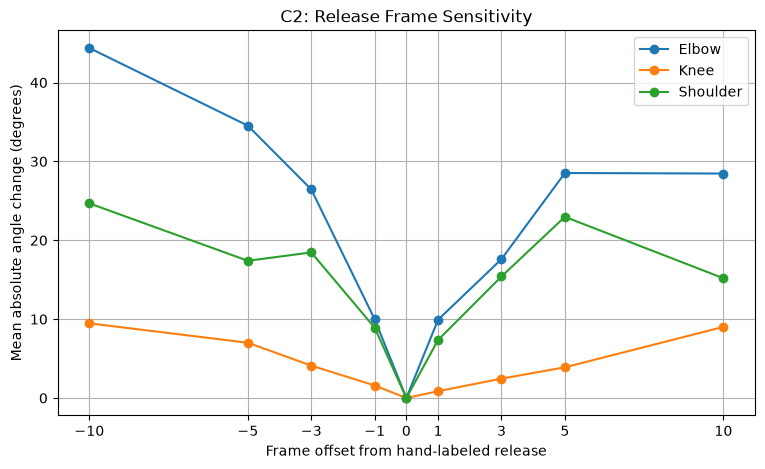

In [31]:
chart_dir = ROOT / "docs/writeups/img"
chart_dir.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(9, 5))

for joint in joints:
    subset = summary[summary["joint"] == joint]

    plt.plot(
        subset["offset"],
        subset["avg_change"],
        marker="o",
        label=joint.replace("_angle", "").capitalize()
    )

plt.xlabel("Frame offset from hand-labeled release")
plt.ylabel("Mean absolute angle change (degrees)")
plt.title("C2: Release Frame Sensitivity")
plt.xticks(offsets)
plt.legend()
plt.grid(True)

plt.savefig(
    chart_dir / "c2_release_sensitivity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [32]:
unusable = sorted(
    set(available) - set(results_df["filename"])
)

print("Clips with no valid comparisons:")
for filename in unusable:
    print(filename)

Clips with no valid comparisons:
Kelvin_Huang_05_Missed.mp4
Rijul_made_03.mp4
Rijul_missed_05.mp4
Veronica_missed_04.mp4


In [2]:
import sys
from pathlib import Path

ROOT = Path("/Users/abbyzhang/Library/CloudStorage/OneDrive-Personal/Cal/NothingButNet/nothingbutnet")

sys.path.insert(0, str(ROOT))

from ml.release_frame_detector import find_release_frame

print("Import successful!")

Import successful!


In [6]:
from ml.release_frame_detector import find_release_frame

video_path = clips_dir / available[0]

pose = extract_pose(str(video_path))
per = angles_for_video(pose["frames"])

elbow_angles = [
    frame["elbow_angle"]
    for frame in per
]

predicted, reason = find_release_frame(
    pose["frames"],
    elbow_angles,
    "right"
)

row = release_df[
    release_df["filename"] == video_path.name
].iloc[0]

true_release = int(row["release_frame"])

print("Video:", video_path.name)
print("True release frame:", true_release)
print("Predicted release frame:", predicted)
print("Reason:", reason)

if predicted is not None:
    print("Absolute error:", abs(predicted - true_release), "frames")

I0000 00:00:1794788542.312914 17795748 gl_context.cc:369] GL version: 2.1 (2.1 Metal - 90.5), renderer: Apple M5
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1794788542.459740 17797078 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1794788542.474285 17797078 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1794788542.497125 17797082 landmark_projection_calculator.cc:186] Using NORM_RECT without IMAGE_DIMENSIONS is only supported for the square ROI. Provide IMAGE_DIMENSIONS or use PROJECTION_MATRIX.


Video: Veronica_made_05.mp4
True release frame: 84
Predicted release frame: 47
Reason: 
Absolute error: 37 frames


In [5]:
import pandas as pd

from ml.pose_extractor import extract_pose
from ml.angle_calculator import angles_for_video

clips_dir = Path("~/clips").expanduser()

release_df = pd.read_csv(
    ROOT / "data/release_frames_all.csv"
)

available = [
    filename
    for filename in release_df["filename"]
    if (clips_dir / filename).exists()
]

print("Videos available:", len(available))

Videos available: 20


In [7]:
for side in ["left", "right"]:
    predicted, reason = find_release_frame(
        pose["frames"],
        elbow_angles,
        side
    )

    print(f"\nShooting side: {side}")
    print("Predicted frame:", predicted)
    print("Reason:", reason)

    if predicted is not None:
        print(
            "Absolute error:",
            abs(predicted - true_release),
            "frames"
        )


Shooting side: left
Predicted frame: 44
Reason: 
Absolute error: 40 frames

Shooting side: right
Predicted frame: 47
Reason: 
Absolute error: 37 frames


In [8]:
for frame in [44, 47, 84]:
    print(f"\nFrame {frame}")
    print("Elbow angle:", per[frame]["elbow_angle"])
    print("Shoulder angle:", per[frame]["shoulder_angle"])
    print("Knee angle:", per[frame]["knee_angle"])
    print(
        "Pose landmarks detected:",
        pose["frames"][frame]["landmarks"] is not None
    )


Frame 44
Elbow angle: 1.7
Shoulder angle: None
Knee angle: None
Pose landmarks detected: True

Frame 47
Elbow angle: 168.9
Shoulder angle: None
Knee angle: None
Pose landmarks detected: True

Frame 84
Elbow angle: 44.9
Shoulder angle: 19.4
Knee angle: None
Pose landmarks detected: True


In [9]:
frame = pose["frames"][84]

print("Frame keys:", frame.keys())

print("\nFirst landmark:")
print(frame["landmarks"][0])

Frame keys: dict_keys(['frame', 'landmarks'])

First landmark:
{'x': 1637.4826574173478, 'y': 761.4064711775187, 'visibility': 0.930232048034668, 'reliable': True}


In [10]:
import numpy as np

frames = pose["frames"]

# Percentage of frames with detected landmarks
pose_coverage = sum(
    frame["landmarks"] is not None
    for frame in frames
) / len(frames)

# Look at 5 frames before and after the true release
window = frames[
    max(0, true_release - 5):
    min(len(frames), true_release + 6)
]

# Landmark visibility around release
visibilities = []

for frame in window:
    landmarks = frame["landmarks"]

    if landmarks is not None:
        for landmark in landmarks:
            if landmark is not None:
                visibilities.append(landmark["visibility"])

avg_visibility = (
    np.mean(visibilities)
    if visibilities else np.nan
)

print("Video:", video_path.name)
print(f"Pose coverage: {pose_coverage:.2%}")
print(f"Average visibility near release: {avg_visibility:.3f}")
print("Release detection error: 37 frames")

Video: Veronica_made_05.mp4
Pose coverage: 85.42%
Average visibility near release: 0.662
Release detection error: 37 frames


In [11]:
print("Release labels columns:")
print(release_df.columns.tolist())

print("\nFeatures columns:")
features_df = pd.read_csv(ROOT / "data/features.csv")
print(features_df.columns.tolist())

Release labels columns:
['filename', 'release_frame', 'made', 'player']

Features columns:
['filename', 'player', 'made', 'side', 'release_frame', 'fps', 'elbow_at_release', 'knee_at_release', 'shoulder_at_release', 'min_knee_before_release', 'min_elbow_before_release', 'dip_to_release_s', 'pose_coverage', 'arm_visibility_at_release']


In [12]:
print(features_df[["filename", "player", "side"]].to_string(index=False))

print("\nSide values:")
print(features_df["side"].value_counts(dropna=False))

print("\nNumber of labeled videos:", len(release_df))
print("Number of feature rows:", len(features_df))

              filename   player  side
    Anisha_Made_01.mp4   Anisha  left
    Anisha_Made_02.mp4   Anisha  left
      Abby_made_01.mp4     Abby  left
      Abby_made_03.mp4     Abby  left
Veronica_missed_01.mp4 Veronica right
Veronica_missed_02.mp4 Veronica right
    Ryan_missed_01.mp4     Ryan right
    Ryan_missed_02.mp4     Ryan right

Side values:
side
left     4
right    4
Name: count, dtype: int64

Number of labeled videos: 20
Number of feature rows: 8


In [13]:
missing_sides = release_df[
    ~release_df["filename"].isin(features_df["filename"])
]

print("Clips without feature rows:")
print(missing_sides[["filename", "player"]].to_string(index=False))

Clips without feature rows:
                  filename       player
      Veronica_made_05.mp4     Veronica
Kelvin_Huang_05_Missed.mp4 Kelvin_Huang
      Veronica_made_03.mp4     Veronica
      Veronica_made_01.mp4     Veronica
    Veronica_missed_03.mp4     Veronica
Kelvin_Huang_08_Missed.mp4 Kelvin_Huang
        Anisha_Made_05.mp4       Anisha
       Rijul_missed_05.mp4        Rijul
    Veronica_missed_04.mp4     Veronica
       Manoj_Missed_07.mp4        Manoj
          Abby_made_02.mp4         Abby
         Rijul_made_03.mp4        Rijul


In [14]:
# Build a lookup from the existing feature dataset
player_sides = (
    features_df
    .dropna(subset=["side"])
    .groupby("player")["side"]
    .first()
    .to_dict()
)

release_df["side"] = release_df["player"].map(player_sides)

print(
    release_df[
        ["filename", "player", "side"]
    ].to_string(index=False)
)

print("\nVideos with unknown shooting hand:")
print(
    release_df[
        release_df["side"].isna()
    ][["filename", "player"]].to_string(index=False)
)

                  filename       player  side
      Veronica_made_05.mp4     Veronica right
Kelvin_Huang_05_Missed.mp4 Kelvin_Huang   NaN
      Veronica_made_03.mp4     Veronica right
      Veronica_made_01.mp4     Veronica right
    Veronica_missed_03.mp4     Veronica right
Kelvin_Huang_08_Missed.mp4 Kelvin_Huang   NaN
        Anisha_Made_05.mp4       Anisha  left
       Rijul_missed_05.mp4        Rijul   NaN
    Veronica_missed_04.mp4     Veronica right
       Manoj_Missed_07.mp4        Manoj   NaN
        Anisha_Made_01.mp4       Anisha  left
        Anisha_Made_02.mp4       Anisha  left
          Abby_made_01.mp4         Abby  left
          Abby_made_02.mp4         Abby  left
          Abby_made_03.mp4         Abby  left
         Rijul_made_03.mp4        Rijul   NaN
    Veronica_missed_01.mp4     Veronica right
    Veronica_missed_02.mp4     Veronica right
        Ryan_missed_01.mp4         Ryan right
        Ryan_missed_02.mp4         Ryan right

Videos with unknown shooting hand

In [15]:
import numpy as np
import pandas as pd

c3_results = []

for _, row in release_df.dropna(subset=["side"]).iterrows():
    filename = row["filename"]
    video_path = clips_dir / filename
    side = row["side"]
    true_release = int(row["release_frame"])

    if not video_path.exists():
        continue

    print("Processing:", filename)

    try:
        pose_data = extract_pose(str(video_path))
        frames = pose_data["frames"]
        per_angles = angles_for_video(frames)

        elbow_angles = [
            a["elbow_angle"] for a in per_angles
        ]

        predicted, reason = find_release_frame(
            frames, elbow_angles, side
        )

        coverage = (
            sum(f["landmarks"] is not None for f in frames)
            / len(frames)
        )

        window = frames[
            max(0, true_release - 5):
            min(len(frames), true_release + 6)
        ]

        visibilities = [
            lm["visibility"]
            for f in window
            if f["landmarks"] is not None
            for lm in f["landmarks"]
            if lm is not None
        ]

        visibility = (
            float(np.mean(visibilities))
            if visibilities else np.nan
        )

        error = (
            abs(predicted - true_release)
            if predicted is not None
            else np.nan
        )

        c3_results.append({
            "filename": filename,
            "player": row["player"],
            "side": side,
            "pose_coverage": coverage,
            "visibility_near_release": visibility,
            "predicted_release": predicted,
            "true_release": true_release,
            "release_error": error,
            "failure_reason": reason
        })

    except Exception as e:
        print("Error:", e)

c3_df = pd.DataFrame(c3_results)

print("\nFinished!")
print(c3_df[
    ["filename", "pose_coverage",
     "visibility_near_release", "release_error"]
].to_string(index=False))

Processing: Veronica_made_05.mp4


I0000 00:00:1794788921.686179 17795748 gl_context.cc:369] GL version: 2.1 (2.1 Metal - 90.5), renderer: Apple M5
W0000 00:00:1794788921.801071 17800910 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1794788921.819603 17800910 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


Processing: Veronica_made_03.mp4


I0000 00:00:1794788927.446992 17795748 gl_context.cc:369] GL version: 2.1 (2.1 Metal - 90.5), renderer: Apple M5
W0000 00:00:1794788927.528128 17800984 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1794788927.545992 17800984 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


Processing: Veronica_made_01.mp4


I0000 00:00:1794788935.555017 17795748 gl_context.cc:369] GL version: 2.1 (2.1 Metal - 90.5), renderer: Apple M5
W0000 00:00:1794788935.630409 17801104 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1794788935.640378 17801107 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


... (21 outputs left out)

I0000 00:00:1794789003.616477 17795748 gl_context.cc:369] GL version: 2.1 (2.1 Metal - 90.5), renderer: Apple M5
W0000 00:00:1794789003.753473 17802056 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1794789003.772206 17802056 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


Processing: Ryan_missed_02.mp4


I0000 00:00:1794789024.037362 17795748 gl_context.cc:369] GL version: 2.1 (2.1 Metal - 90.5), renderer: Apple M5
W0000 00:00:1794789024.171983 17802408 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1794789024.222967 17802417 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.



Finished!
              filename  pose_coverage  visibility_near_release  release_error
  Veronica_made_05.mp4       0.854167                 0.662229           37.0
  Veronica_made_03.mp4       0.854730                 0.859414            2.0
  Veronica_made_01.mp4       0.989170                 0.859856            NaN
Veronica_missed_03.mp4       0.868778                 0.891880           13.0
    Anisha_Made_05.mp4       1.000000                 0.893126            NaN
Veronica_missed_04.mp4       0.992958                 0.429111            NaN
    Anisha_Made_01.mp4       1.000000                 0.869294            3.0
    Anisha_Made_02.mp4       1.000000                 0.872874            2.0
      Abby_made_01.mp4       0.948387                 0.825491          102.0
      Abby_made_02.mp4       0.982456                 0.831562          123.0
      Abby_made_03.mp4       0.951890                 0.883539            2.0
Veronica_missed_01.mp4       0.715000                

In [16]:
print("Videos evaluated:", len(c3_df))

print(
    "Successful release predictions:",
    c3_df["release_error"].notna().sum()
)

print(
    "Failed release predictions:",
    c3_df["release_error"].isna().sum()
)

Videos evaluated: 15
Successful release predictions: 12
Failed release predictions: 3


In [17]:
print(
    c3_df[
        ["filename", "pose_coverage",
         "visibility_near_release",
         "true_release", "predicted_release",
         "release_error", "failure_reason"]
    ].to_string(index=False)
)

              filename  pose_coverage  visibility_near_release  true_release  predicted_release  release_error                      failure_reason
  Veronica_made_05.mp4       0.854167                 0.662229            84               47.0           37.0                                    
  Veronica_made_03.mp4       0.854730                 0.859414           183              185.0            2.0                                    
  Veronica_made_01.mp4       0.989170                 0.859856            56                NaN            NaN Wrist never goes above the shoulder
Veronica_missed_03.mp4       0.868778                 0.891880            83               96.0           13.0                                    
    Anisha_Made_05.mp4       1.000000                 0.893126            77                NaN            NaN Wrist never goes above the shoulder
Veronica_missed_04.mp4       0.992958                 0.429111            31                NaN            NaN Wrist n

In [18]:
print("Average release error:",
      c3_df["release_error"].mean())

print("Median release error:",
      c3_df["release_error"].median())

print("Maximum release error:",
      c3_df["release_error"].max())

print("\nFailed detections:")
print(
    c3_df[c3_df["release_error"].isna()][
        ["filename", "failure_reason"]
    ].to_string(index=False)
)

Average release error: 64.33333333333333
Median release error: 61.5
Maximum release error: 179.0

Failed detections:
              filename                      failure_reason
  Veronica_made_01.mp4 Wrist never goes above the shoulder
    Anisha_Made_05.mp4 Wrist never goes above the shoulder
Veronica_missed_04.mp4 Wrist never goes above the shoulder


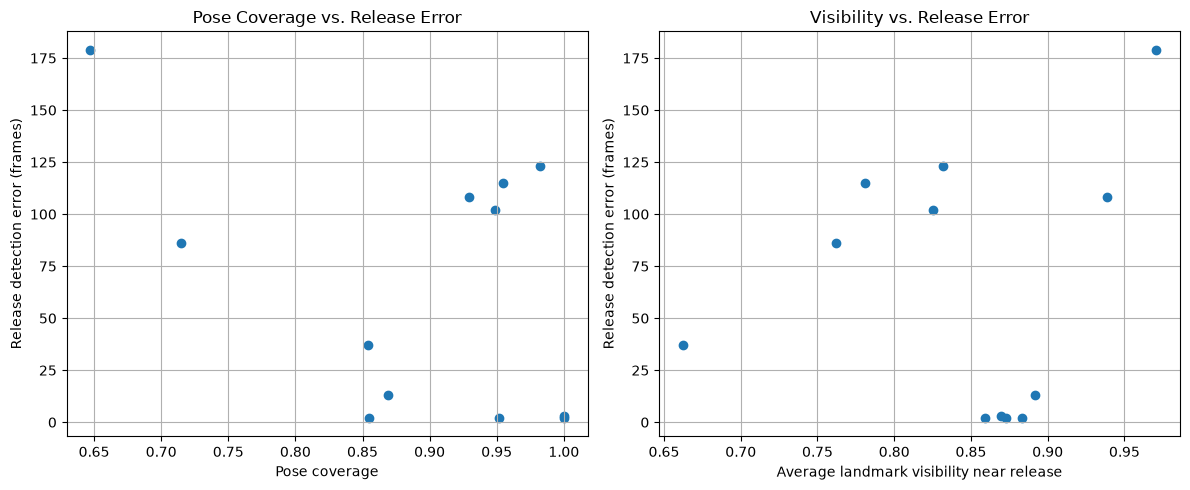

In [19]:
import matplotlib.pyplot as plt

chart_dir = ROOT / "docs/writeups/img"
chart_dir.mkdir(parents=True, exist_ok=True)

valid_c3 = c3_df.dropna(subset=["release_error"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(
    valid_c3["pose_coverage"],
    valid_c3["release_error"]
)
axes[0].set_xlabel("Pose coverage")
axes[0].set_ylabel("Release detection error (frames)")
axes[0].set_title("Pose Coverage vs. Release Error")
axes[0].grid(True)

axes[1].scatter(
    valid_c3["visibility_near_release"],
    valid_c3["release_error"]
)
axes[1].set_xlabel("Average landmark visibility near release")
axes[1].set_ylabel("Release detection error (frames)")
axes[1].set_title("Visibility vs. Release Error")
axes[1].grid(True)

plt.tight_layout()
plt.savefig(
    chart_dir / "c3_confidence_vs_error.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [20]:
print("Pose coverage correlation:",
      valid_c3["pose_coverage"].corr(
          valid_c3["release_error"]
      ))

print("Visibility correlation:",
      valid_c3["visibility_near_release"].corr(
          valid_c3["release_error"]
      ))

Pose coverage correlation: -0.42393199712017526
Visibility correlation: 0.14300278540332806
